In [7]:
import pandas as pd
import numpy as np
df=pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [8]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [9]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [10]:
df.shape

(1025, 14)

In [11]:
X=df.drop("target",axis=1)
y=df["target"]

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,random_state=42,test_size=0.2)

In [13]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
Xtrain=scaler.fit_transform(Xtrain)
Xtest=scaler.transform(Xtest)

In [14]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier()
model.fit(Xtrain,ytrain)

RandomForestClassifier()

In [15]:
y_pred=model.predict(Xtest)
print("Acuracy score",accuracy_score(ytest,y_pred))

Acuracy score 0.9853658536585366


In [16]:
print("Classification report:",classification_report(ytest,y_pred))
print("Confusion matrix:",confusion_matrix(ytest,y_pred))

Classification report:               precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

Confusion matrix: [[102   0]
 [  3 100]]


In [17]:
input_data = [[55, 1, 2, 140, 250, 0, 1, 150, 0, 1.5, 1, 0, 2]]
input_data_scaled=scaler.transform(input_data)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [18]:
input_predict=model.predict(input_data_scaled)
print(input_predict)

[1]


In [19]:
from sklearn.linear_model import LogisticRegression
log_model=LogisticRegression()
log_model.fit(Xtrain,ytrain)

LogisticRegression()

In [20]:
y_pred_log=log_model.predict(Xtest)
print("Accuracy of Log_regression:",accuracy_score(ytest,y_pred_log))

Accuracy of Log_regression: 0.7951219512195122


In [21]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier()
dt_model.fit(Xtrain,ytrain)



DecisionTreeClassifier()

In [22]:
y_pred_dt=dt_model.predict(Xtest)
print("Accuracy of DT model:",accuracy_score(ytest,y_pred_dt))

Accuracy of DT model: 0.9853658536585366


In [23]:
from sklearn.svm import SVC
svm_model=SVC(C=1.5,
    kernel="rbf",
    gamma="scale",
    probability=True,
    random_state=42,
)
svm_model.fit(Xtrain,ytrain)

SVC(C=1.5, probability=True, random_state=42)

In [24]:
y_pred_svm=svm_model.predict(Xtest)
print("Accuracy of svm model:",accuracy_score(ytest,y_pred_svm))

Accuracy of svm model: 0.8975609756097561


In [25]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier(n_neighbors=5,
    weights="distance",
    metric="minkowski",
    p=2,)
knn_model.fit(Xtrain,ytrain)

KNeighborsClassifier(weights='distance')

In [26]:
y_pred_knn=knn_model.predict(Xtest)
print("Accuracy of Knn:",accuracy_score(ytest,y_pred_knn))

Accuracy of Knn: 1.0


In [27]:
from sklearn.naive_bayes import GaussianNB
nb_model=GaussianNB(var_smoothing=1e-9)
nb_model.fit(Xtrain,ytrain)

GaussianNB()

In [28]:
y_pred_nb=nb_model.predict(Xtest)
print("Accuracy of NB model:",accuracy_score
      (ytest,y_pred_nb))

Accuracy of NB model: 0.8


In [29]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda_model=LinearDiscriminantAnalysis(solver="svd")
lda_model.fit(Xtrain,ytrain)

LinearDiscriminantAnalysis()

In [30]:
y_pred_lda=lda_model.predict(Xtest)
print("Accuracy of lda model:",accuracy_score(ytest,y_pred_lda))

Accuracy of lda model: 0.8195121951219512


In [31]:
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
    VotingClassifier,
)

In [32]:
ada_model=AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42,)
ada_model.fit(Xtrain,ytrain)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                    random_state=42),
                   learning_rate=0.5, n_estimators=100, random_state=42)

In [33]:
y_pred_ada=ada_model.predict(Xtest)
print("Accuracy of Ada:",accuracy_score(ytest,y_pred_ada))

Accuracy of Ada: 0.8634146341463415


In [34]:
et_model=ExtraTreesClassifier(n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1,)
et_model.fit(Xtrain,ytrain)


ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [35]:
y_pred_et=et_model.predict(Xtest)
print("Accuracy of etratrees:",accuracy_score(ytest,y_pred_et))

Accuracy of etratrees: 1.0


In [36]:
gb_model=GradientBoostingClassifier(n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42,)
gb_model.fit(Xtrain,ytrain)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42, subsample=0.8)

In [37]:
y_pred_gb=gb_model.predict(Xtest)
print("Accuracy of GB:",accuracy_score(ytest,y_pred_gb))

Accuracy of GB: 0.9512195121951219


In [38]:
voting_model=VotingClassifier(estimators=[("rf",model),("log",log_model),("dt",dt_model),("svm",svm_model),("knn",knn_model)],voting="hard")
voting_model.fit(Xtrain,ytrain)


VotingClassifier(estimators=[('rf', RandomForestClassifier()),
                             ('log', LogisticRegression()),
                             ('dt', DecisionTreeClassifier()),
                             ('svm',
                              SVC(C=1.5, probability=True, random_state=42)),
                             ('knn', KNeighborsClassifier(weights='distance'))])

In [39]:
y_pred_vote=voting_model.predict(Xtest)

In [40]:
print("Accuracy by voting:",accuracy_score(ytest,y_pred_vote))

Accuracy by voting: 1.0


In [42]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 35.2 MB/s  0:00:02


In [43]:
from catboost import CatBoostClassifier
cat_model=CatBoostClassifier(iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=0,)
cat_model.fit(Xtrain,ytrain)

CatBoostClassifier(depth=6, iterations=500, learning_rate=0.05, random_seed=42, verbose=0)

In [44]:
y_pred_cat=cat_model.predict(Xtest)
print("Accuracy of cat:",accuracy_score(ytest,y_pred_cat))

Accuracy of cat: 0.9853658536585366


In [45]:
from xgboost import XGBClassifier
xgb_model=XGBClassifier(n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,)
xgb_model.fit(Xtrain,ytrain)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [46]:
y_pred_xgb=xgb_model.predict(Xtest)
print("Accuracy of xgb:",accuracy_score(ytest,y_pred_xgb))

Accuracy of xgb: 0.9853658536585366


In [47]:
from lightgbm import LGBMClassifier
lgb_model=LGBMClassifier(n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=20,
    random_state=42,
    verbose=-1,)
lgb_model.fit(Xtrain,ytrain)

LGBMClassifier(learning_rate=0.05, n_estimators=200, num_leaves=15,
               random_state=42, verbose=-1)

In [48]:
y_pred_lgb=lgb_model.predict(Xtest)
print("Accuracy of lgb:",accuracy_score(ytest,y_pred_lgb))

Accuracy of lgb: 0.9853658536585366


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [50]:
!pip install pytorch-tabnet

In [51]:
import numpy as np
from pytorch_tabnet.tab_model import TabNetClassifier


In [52]:
import numpy as np
import pandas as pd
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Convert scaled train/test arrays to contiguous float32 NumPy arrays
X_train_np = np.ascontiguousarray(Xtrain, dtype=np.float32)
y_train_np = np.ascontiguousarray(ytrain)
X_test_np = np.ascontiguousarray(Xtest, dtype=np.float32)
y_test_np = np.ascontiguousarray(ytest)

# 2. Initialize TabNetClassifier
tab_model = TabNetClassifier(
    n_d=8,
    n_a=8,
    n_steps=3,
    gamma=1.3,
    seed=42,
    verbose=0,
)

# 3. Train with validation eval_set and early stopping
tab_model.fit(
    X_train=X_train_np,
    y_train=y_train_np,
    eval_set=[(X_test_np, y_test_np)],
    eval_name=["test"],
    eval_metric=["accuracy"],
    max_epochs=150,
    patience=20,
    batch_size=64,
)

# 4. Predict and evaluate
y_pred_tab = tab_model.predict(X_test_np)
print("Accuracy of TabNet:", accuracy_score(y_test_np, y_pred_tab))
print("\nClassification Report:\n", classification_report(y_test_np, y_pred_tab))
print("Confusion Matrix:\n", confusion_matrix(y_test_np, y_pred_tab))

# 5. View global feature importances
tab_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tab_model.feature_importances_,
}).sort_values(by="Importance", ascending=False)

display(tab_importance)

# 6. Predict on a new patient sample (preserving column names)
sample_df = pd.DataFrame(
    [[55, 1, 2, 140, 250, 0, 1, 150, 0, 1.5, 1, 0, 2]],
    columns=X.columns,
)
sample_scaled = np.ascontiguousarray(scaler.transform(sample_df), dtype=np.float32)
print("Predicted target:", tab_model.predict(sample_scaled))
print("Class probabilities:", tab_model.predict_proba(sample_scaled))



Early stopping occurred at epoch 139 with best_epoch = 119 and best_test_accuracy = 0.98537
Accuracy of TabNet: 0.9853658536585366

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       102
           1       1.00      0.97      0.99       103

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

Confusion Matrix:
 [[102   0]
 [  3 100]]


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


,Feature,Importance
11,ca,0.259274
12,thal,0.159882
9,oldpeak,0.154945
2,cp,0.107785
4,chol,0.100539
5,fbs,0.068742
8,exang,0.065414
6,restecg,0.036291
10,slope,0.034923
3,trestbps,0.004238


Predicted target: [0]
Class probabilities: [[0.70668817 0.29331186]]


,Model,Accuracy,Accuracy (%)
0,KNN,1.000000,100.000000
1,Voting Classifier,1.000000,100.000000
2,Extra Trees,1.000000,100.000000
3,CatBoost,0.985366,98.536585
4,XGBoost,0.985366,98.536585
5,Decision Tree,0.985366,98.536585
6,Random Forest,0.985366,98.536585
7,LightGBM,0.985366,98.536585
8,TabNet,0.985366,98.536585
9,Gradient Boosting,0.951220,95.121951


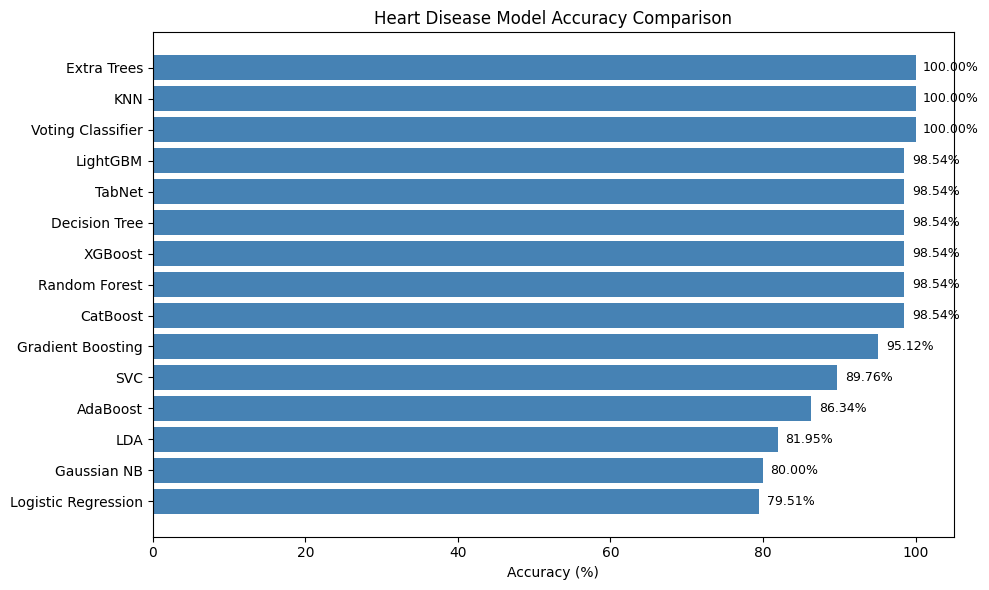

In [53]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# Collect predictions from models already fitted in your notebook
model_predictions = {
    "Random Forest": y_pred,
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_dt,
    "SVC": y_pred_svm,
    "KNN": y_pred_knn,
    "Gaussian NB": y_pred_nb,
    "LDA": y_pred_lda,
    "AdaBoost": y_pred_ada,
    "Extra Trees": y_pred_et,
    "Gradient Boosting": y_pred_gb,
    "Voting Classifier": y_pred_vote,
    "CatBoost": y_pred_cat,
    "XGBoost": y_pred_xgb,
    "LightGBM": y_pred_lgb,
    "TabNet": y_pred_tab,
}

# Build sorted comparison DataFrame
results = []
for name, preds in model_predictions.items():
  acc = accuracy_score(ytest, preds)
  results.append({"Model": name, "Accuracy": acc, "Accuracy (%)": acc * 100})

comparison_df = (
    pd.DataFrame(results)
    .sort_values(by="Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df)

# Plot side-by-side / ranked accuracy bar chart
plot_df = comparison_df.sort_values(by="Accuracy", ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(plot_df["Model"], plot_df["Accuracy (%)"], color="steelblue")
plt.xlabel("Accuracy (%)")
plt.title("Heart Disease Model Accuracy Comparison")
plt.xlim(0, 105)

for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 1.0,
      bar.get_y() + bar.get_height() / 2,
      f"{width:.2f}%",
      va="center",
      fontsize=9,
  )

plt.tight_layout()
plt.show()